# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
iris = load_iris()
df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
df['target'] = iris.target

print("Перші 5 рядків набору даних Iris:")
display(df.head())

Перші 5 рядків набору даних Iris:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

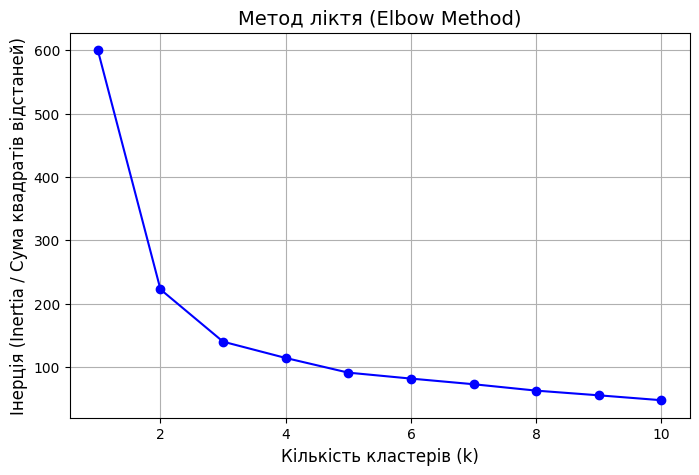

In [4]:
X = iris.data


scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


inertia = []
K_range = range(1, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b')
plt.xlabel('Кількість кластерів (k)', fontsize=12)
plt.ylabel('Інерція (Inertia / Сума квадратів відстаней)', fontsize=12)
plt.title('Метод ліктя (Elbow Method)', fontsize=14)
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

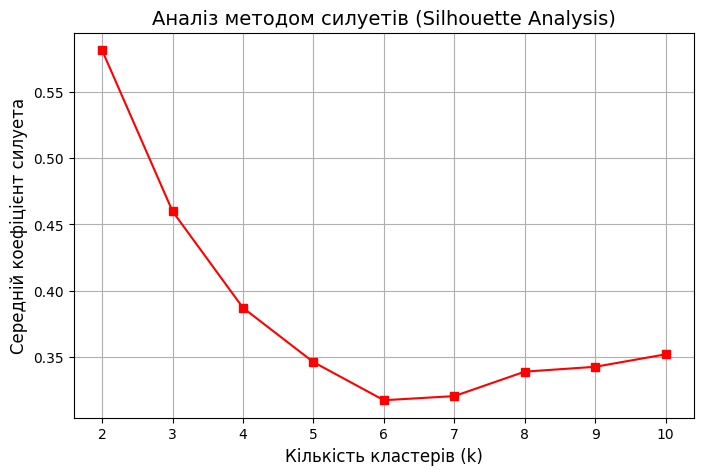

In [5]:
silhouette_scores = []
K_silhouette_range = range(2, 11)

for k in K_silhouette_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  cluster_labels = kmeans.fit_predict(X_scaled)
  score = silhouette_score(X_scaled, cluster_labels)
  silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K_silhouette_range, silhouette_scores, marker='s', linestyle='-', color='r')
plt.xlabel('Кількість кластерів (k)', fontsize=12)
plt.ylabel('Середній коефіцієнт силуета', fontsize=12)
plt.title('Аналіз методом силуетів (Silhouette Analysis)', fontsize=14)
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

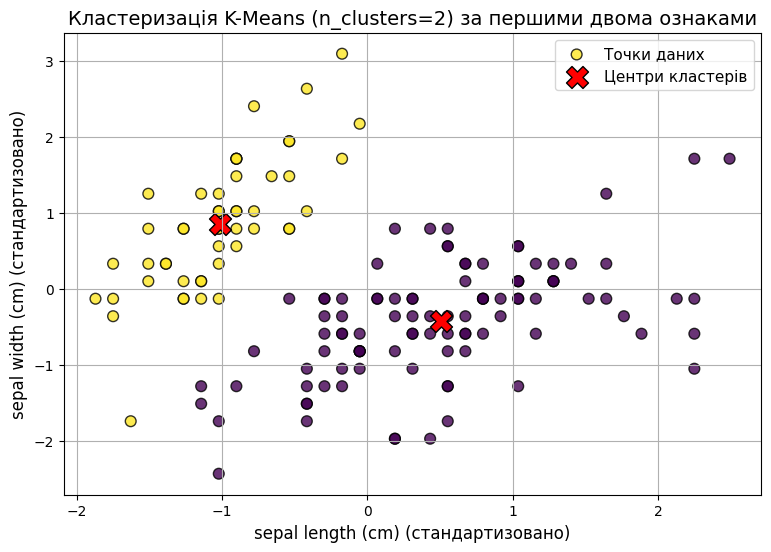

Координати центрів кластерів (у стандартизованому просторі):
[[ 0.50728948 -0.42663134  0.65249366  0.62744675]
 [-1.01457897  0.85326268 -1.30498732 -1.25489349]]


In [6]:
kmeans_final = KMeans(n_clusters=2, random_state=42, n_init=10)
y_kmeans = kmeans_final.fit_predict(X_scaled)

# Візуалізація перших двох ознак та центрів кластерів
plt.figure(figsize=(9, 6))
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=y_kmeans,
    cmap='viridis',
    s=60,
    edgecolors='k',
    alpha=0.8,
    label='Точки даних',
)

# Координати центрів кластерів
centers = kmeans_final.cluster_centers_
plt.scatter(
    centers[:, 0],
    centers[:, 1],
    c='red',
    s=250,
    marker='X',
    edgecolors='black',
    label='Центри кластерів',
)

plt.xlabel(iris.feature_names[0] + ' (стандартизовано)', fontsize=12)
plt.ylabel(iris.feature_names[1] + ' (стандартизовано)', fontsize=12)
plt.title(
    'Кластеризація K-Means (n_clusters=2) за першими двома ознаками',
    fontsize=14,
)
plt.legend(fontsize=11)
plt.grid(True)
plt.show()

print('Координати центрів кластерів (у стандартизованому просторі):')
print(centers)

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Порівняння методів:
За методом ліктя чіткого «злому» (точки перегину) кривої інерції немає, проте спостерігається помітне плато після $k=2$ або $k=3$.За методом силуетів максимальне значення середнього коефіцієнта силуета досягається при $k = 2$, що вказує на найбільшу внутрішню згуртованість та відокремленість кластерів саме для цієї кількості.
Чому обрано два кластери ($n\_clusters=2$): Хоча набір даних Iris містить три види квітів (setosa, versicolor, virginica), два з них (versicolor та virginica) мають значне перекриття у багатовимірному просторі ознак і погано розділяються без вчителя ( unsupervised learning). Клас setosa є повністю відокремленим від інших. Тому алгоритм без учителя чітко виділяє 2 основні групи: 1) клас setosa та 2) об'єднану групу двох інших видів. Це повністю узгоджується як з графіком силуетів (де $k=2$ дає найкращий показник), так і з геометричним розташуванням даних.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [9]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [10]:
print("Список стовпців у наборі даних про студентів:")
print(list(df.columns))


display(df.dtypes)

Список стовпців у наборі даних про студентів:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


,0
StudentID,int64
Age,int64
Gender,int64
Ethnicity,int64
ParentalEducation,int64
StudyTimeWeekly,float64
Absences,int64
Tutoring,int64
ParentalSupport,int64
Extracurricular,int64


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [12]:
print(df.isnull().sum())

StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [13]:
print(df.duplicated().sum())

0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [14]:
display(df.describe())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [15]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [16]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search.fit(X_train_scaled, y_train)

best_rf = grid_search.best_estimator_
y_pred = best_rf.predict(X_test_scaled)
test_acc = accuracy_score(y_test, y_pred)

print("Найкращі параметри:", grid_search.best_params_)
print(f"Середня CV-точність: {grid_search.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc:.4f}")

Найкращі параметри: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Середня CV-точність: 0.9237
Тестова accuracy: 0.9144


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [17]:
param_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['saga'],
    'max_iter': [5000]
}

lr = LogisticRegression(random_state=42)
grid_search_lr = GridSearchCV(estimator=lr, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_lr.fit(X_train_scaled, y_train)

best_lr = grid_search_lr.best_estimator_
y_pred_lr = best_lr.predict(X_test_scaled)
test_acc_lr = accuracy_score(y_test, y_pred_lr)

print("Найкращі параметри:", grid_search_lr.best_params_)
print(f"Середня CV-точність: {grid_search_lr.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_lr:.4f}")

Найкращі параметри: {'C': 0.1, 'max_iter': 5000, 'penalty': 'l1', 'solver': 'saga'}
Середня CV-точність: 0.7961
Тестова accuracy: 0.7662


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [18]:
param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']
}

svm = SVC(random_state=42)
grid_search_svm = GridSearchCV(estimator=svm, param_grid=param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_search_svm.fit(X_train_scaled, y_train)

best_svm = grid_search_svm.best_estimator_
y_pred_svm = best_svm.predict(X_test_scaled)
test_acc_svm = accuracy_score(y_test, y_pred_svm)

print("Найкращі параметри:", grid_search_svm.best_params_)
print(f"Середня CV-точність: {grid_search_svm.best_score_:.4f}")
print(f"Тестова accuracy: {test_acc_svm:.4f}")

Найкращі параметри: {'C': 100, 'gamma': 'scale', 'kernel': 'linear'}
Середня CV-точність: 0.8625
Тестова accuracy: 0.8246


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [19]:
results = pd.DataFrame({
    'Модель': ['Random Forest', 'Logistic Regression', 'SVM'],
    'CV Accuracy': [grid_search.best_score_, grid_search_lr.best_score_, grid_search_svm.best_score_],
    'Test Accuracy': [test_acc, test_acc_lr, test_acc_svm]
})

display(results)

models = {
    'Random Forest': (grid_search.best_score_, y_pred),
    'Logistic Regression': (grid_search_lr.best_score_, y_pred_lr),
    'SVM': (grid_search_svm.best_score_, y_pred_svm)
}

best_model_name = max(models, key=lambda k: models[k][0])
best_y_pred = models[best_model_name][1]

print(f"Найкраща модель за CV-точністю: {best_model_name}")
print(classification_report(y_test, best_y_pred))

,Модель,CV Accuracy,Test Accuracy
0,Random Forest,0.923674,0.914405
1,Logistic Regression,0.796129,0.766180
2,SVM,0.862518,0.824635


Найкраща модель за CV-точністю: Random Forest
              precision    recall  f1-score   support

         0.0       0.83      0.45      0.59        22
         1.0       0.81      0.88      0.84        49
         2.0       0.94      0.87      0.90        85
         3.0       0.90      0.90      0.90        86
         4.0       0.94      0.99      0.96       237

    accuracy                           0.91       479
   macro avg       0.88      0.82      0.84       479
weighted avg       0.91      0.91      0.91       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

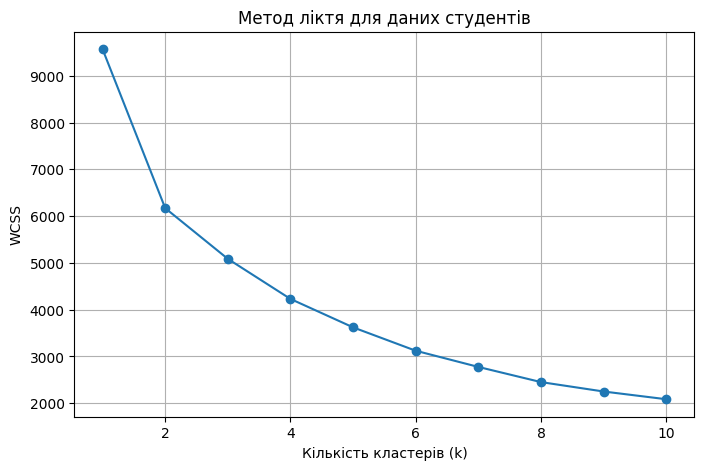

In [20]:
features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_cluster = df[features]

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_cluster_scaled)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss, marker='o', linestyle='-')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.title('Метод ліктя для даних студентів')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

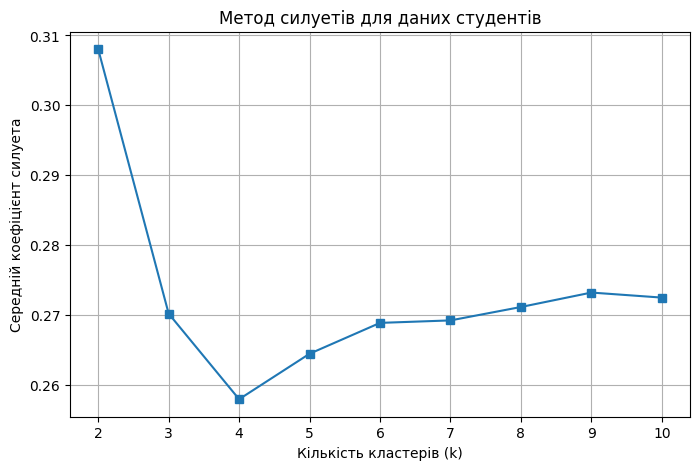

In [21]:
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_cluster_scaled)
    score = silhouette_score(X_cluster_scaled, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8, 5))
plt.plot(K_range, silhouette_scores, marker='s', linestyle='-')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Середній коефіцієнт силуета')
plt.title('Метод силуетів для даних студентів')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [23]:
!pip install kneed yellowbrick

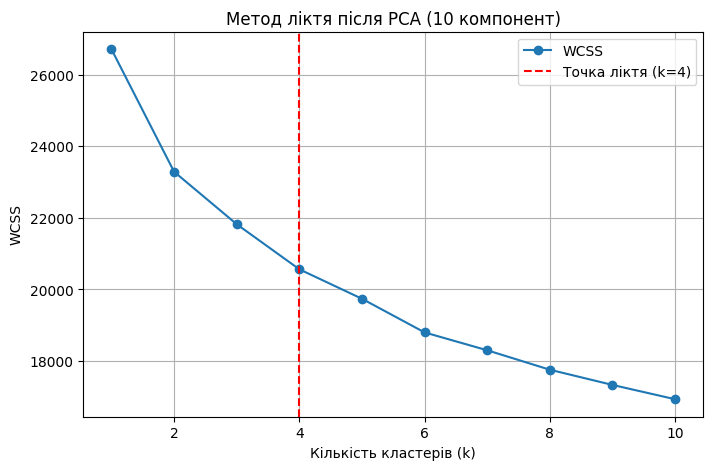

Обрано головних компонент: 10 (пояснена дисперсія: 85.91%)
Автоматично визначена точка ліктя: k = 4


In [32]:
from kneed import KneeLocator

X_all = df.drop(columns=['StudentID', 'GradeClass'])

scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

pca = PCA()
pca.fit(X_all_scaled)

cum_var = np.cumsum(pca.explained_variance_ratio_)
n_components = np.argmax(cum_var >= 0.80) + 1

pca_final = PCA(n_components=n_components)
X_pca = pca_final.fit_transform(X_all_scaled)

wcss_pca = []
K_range = range(1, 11)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_pca)
  wcss_pca.append(kmeans.inertia_)

kl = KneeLocator(
    list(K_range), wcss_pca, curve='convex', direction='decreasing'
)
optimal_k = kl.elbow

plt.figure(figsize=(8, 5))
plt.plot(K_range, wcss_pca, marker='o', linestyle='-', label='WCSS')
plt.axvline(
    x=optimal_k, color='r', linestyle='--', label=f'Точка ліктя (k={optimal_k})'
)
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('WCSS')
plt.title(f'Метод ліктя після PCA ({n_components} компонент)')
plt.legend()
plt.grid(True)
plt.show()

print(
    f'Обрано головних компонент: {n_components} (пояснена дисперсія:'
    f' {cum_var[n_components-1]:.2%})'
)
print(f'Автоматично визначена точка ліктя: k = {optimal_k}')

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [33]:
import numpy as np
from sklearn.decomposition import PCA
from kneed import KneeLocator

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [34]:
X_all = df.drop(columns=['StudentID', 'GradeClass'])

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [36]:

scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

pca = PCA()
pca.fit(X_all_scaled)

explained_variance_ratio = pca.explained_variance_ratio_
cum_var = np.cumsum(explained_variance_ratio)

for i, var in enumerate(explained_variance_ratio, 1):
    print(f"Компонента {i}: {var:.4f} (накопичена: {cum_var[i-1]:.4f})")

Компонента 1: 0.1525 (накопичена: 0.1525)
Компонента 2: 0.0861 (накопичена: 0.2386)
Компонента 3: 0.0827 (накопичена: 0.3213)
Компонента 4: 0.0807 (накопичена: 0.4020)
Компонента 5: 0.0786 (накопичена: 0.4806)
Компонента 6: 0.0779 (накопичена: 0.5586)
Компонента 7: 0.0763 (накопичена: 0.6349)
Компонента 8: 0.0760 (накопичена: 0.7109)
Компонента 9: 0.0744 (накопичена: 0.7853)
Компонента 10: 0.0738 (накопичена: 0.8591)
Компонента 11: 0.0717 (накопичена: 0.9308)
Компонента 12: 0.0675 (накопичена: 0.9982)
Компонента 13: 0.0018 (накопичена: 1.0000)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

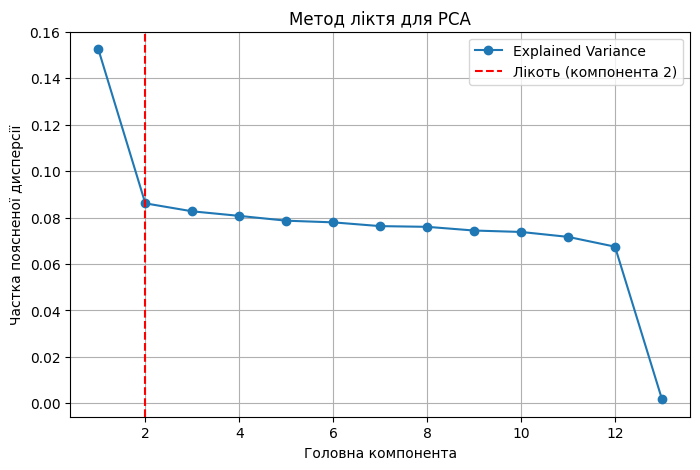

2


In [37]:
components = range(1, len(pca.explained_variance_ratio_) + 1)
kl = KneeLocator(components, pca.explained_variance_ratio_, curve='convex', direction='decreasing')
optimal_components = kl.elbow

plt.figure(figsize=(8, 5))
plt.plot(components, pca.explained_variance_ratio_, marker='o', linestyle='-', label='Explained Variance')
plt.axvline(x=optimal_components, color='r', linestyle='--', label=f'Лікоть (компонента {optimal_components})')
plt.xlabel('Головна компонента')
plt.ylabel('Частка поясненої дисперсії')
plt.title('Метод ліктя для PCA')
plt.legend()
plt.grid(True)
plt.show()

print(optimal_components)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

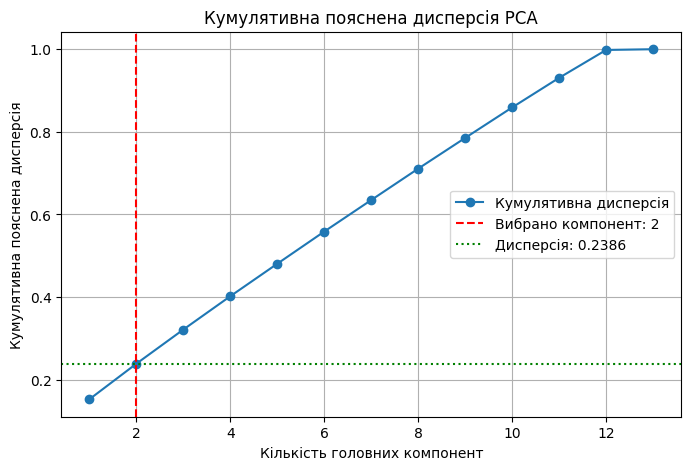

Вибрана кількість компонент: 2
Фактична частка поясненої дисперсії: 0.2386


In [38]:
cum_var = np.cumsum(pca.explained_variance_ratio_)
n_components = optimal_components

pca_final = PCA(n_components=n_components)
X_pca = pca_final.fit_transform(X_all_scaled)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='-', label='Кумулятивна дисперсія')
plt.axvline(x=n_components, color='r', linestyle='--', label=f'Вибрано компонент: {n_components}')
plt.axhline(y=cum_var[n_components - 1], color='g', linestyle=':', label=f'Дисперсія: {cum_var[n_components - 1]:.4f}')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.title('Кумулятивна пояснена дисперсія PCA')
plt.legend()
plt.grid(True)
plt.show()

print(f"Вибрана кількість компонент: {n_components}")
print(f"Фактична частка поясненої дисперсії: {cum_var[n_components - 1]:.4f}")

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [39]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

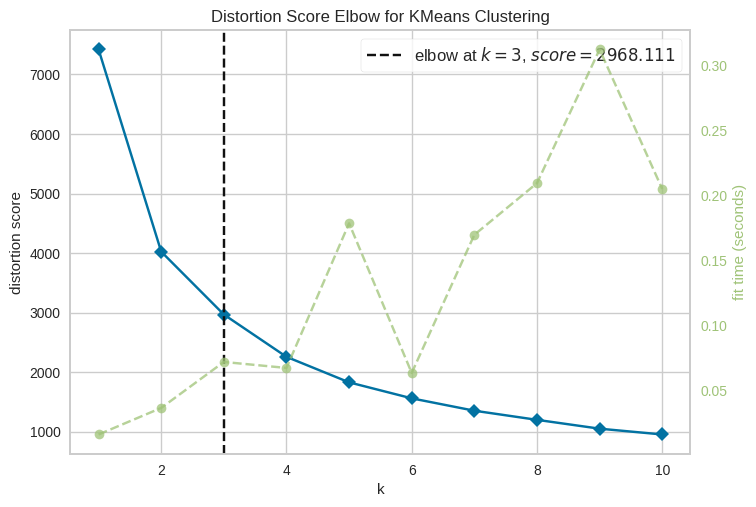

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [40]:
model = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model, k=(1, 11))

visualizer.fit(X_pca)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Методи ліктя та силуетів на 4 числових ознаках вказують на поділ на 2–3 кластери, тоді як метод ліктя після PCA дає оптимальне значення $k=4$. За допомогою KneeLocator для PCA було визначено 2 головні компоненти, які охоплюють 23.86% кумулятивної дисперсії вихідних даних.   Класифікація використовує мітки GradeClass для навчання моделей з учителем задля прогнозування оцінок, тоді як кластеризація є навчанням без учителя, що групує студентів за природними поведінковими характеристиками у просторі ознак без прив'язки до цільової змінної.